Ejercicio 1: KMeans Wine: Cargar las librerías y el dataset.

In [2]:
# Importar las librerías necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score
from sklearn.decomposition import PCA

In [3]:
# Cargar el conjunto de datos Wine
wine = load_wine()

# Crear el DataFrame con las variables predictoras
X = pd.DataFrame(wine.data, columns=wine.feature_names)

# Mostrar las primeras filas
print(X.head())

# Información general
print("\nDimensiones:", X.shape)
print("\nTipos de variables:")
print(X.dtypes)
print("\nDescripción estadística:")
print(X.describe())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0                  

Revisar valores nulos:

In [4]:
# Revisar valores nulos
print("Valores nulos:")
print(X.isnull().sum())

print("\nTotal de valores nulos:", X.isnull().sum().sum())

Valores nulos:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total de valores nulos: 0


Estandarizar los datos:

In [5]:
# Estandarizar las variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Datos estandarizados correctamente.")

Datos estandarizados correctamente.


Implementar K-MEANS con diferentes valores de K:

In [6]:
# Probar diferentes valores de K
resultados = []

for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_scaled)

    inercia = modelo.inertia_
    silhouette = silhouette_score(X_scaled, etiquetas)

    resultados.append([k, inercia, silhouette])

# Mostrar resultados
tabla = pd.DataFrame(
    resultados,
    columns=["K", "Inercia", "Silhouette Score"]
)

print(tabla)

   K      Inercia  Silhouette Score
0  2  1658.758852          0.259317
1  3  1277.928489          0.284859
2  4  1175.428333          0.260170
3  5  1109.512739          0.201619
4  6  1046.002333          0.237167


Gráfica del método codo:

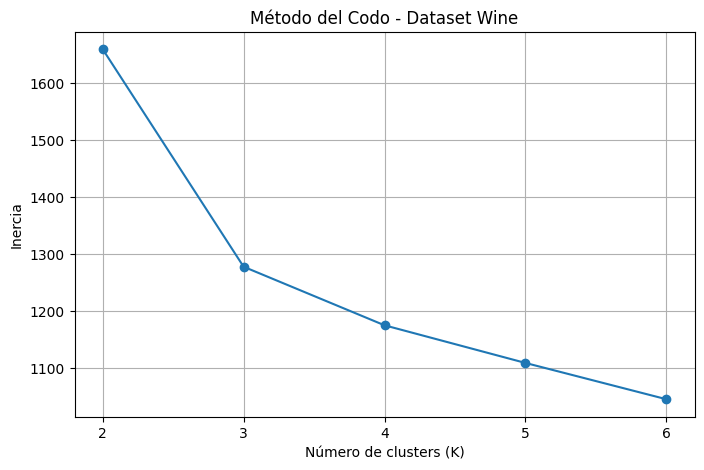

In [7]:
# Gráfica del Método del Codo
plt.figure(figsize=(8, 5))

plt.plot(tabla["K"], tabla["Inercia"], marker="o")

plt.title("Método del Codo - Dataset Wine")
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.xticks(range(2, 7))
plt.grid()
plt.show()

Se observa lo siguiente:
- La inercia disminuye a medida que aumentan los clusteres.
- El mejor Silhouette Score se obtiene con k = 3 (0.2849)
- La gráfica dle codo muestra una reduccion importante de la inercia entre K = 2 y K = 3.
La desición será utilziar K = 3 , porque presenta el mejor Silhouette Score y ofrece una segmentación equilibrada para continuar el análisis.


Ejecutar el modelo:

In [8]:
# Modelo definitivo con 3 clusters
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(X_scaled)

# Agregar los clusters al conjunto de datos
X_resultado = X.copy()
X_resultado["Cluster"] = clusters

print(X_resultado.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  Cluster  
0         

Calcular las métricas de evaluación:

In [9]:
# Calcular métricas del modelo definitivo
silhouette = silhouette_score(X_scaled, clusters)
davies = davies_bouldin_score(X_scaled, clusters)
calinski = calinski_harabasz_score(X_scaled, clusters)

print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", davies)
print("Calinski-Harabasz Score:", calinski)

Silhouette Score: 0.2848589191898987
Davies-Bouldin Index: 1.3891879777181646
Calinski-Harabasz Score: 70.9400080031512


Aplicar PCA para visualizar los clusters:

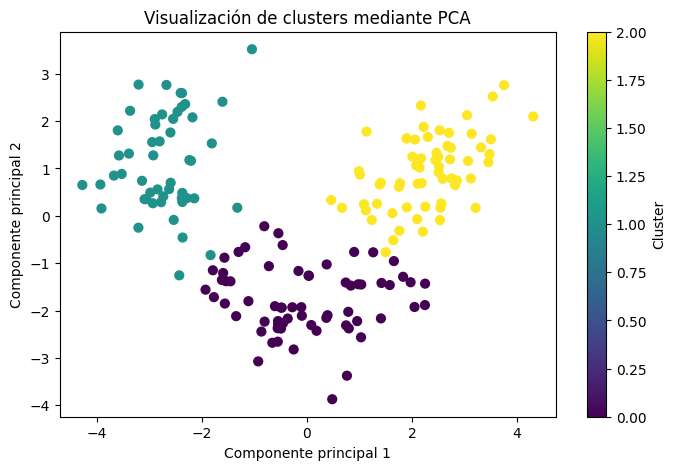

Varianza explicada: [0.36198848 0.1920749 ]
Varianza total: 0.5540633835693526


In [10]:
# Aplicar PCA con dos componentes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Crear gráfica de los clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    s=40
)

plt.title("Visualización de clusters mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.colorbar(label="Cluster")
plt.show()

# Varianza explicada
print("Varianza explicada:", pca.explained_variance_ratio_)
print("Varianza total:", sum(pca.explained_variance_ratio_))

Analizar las características de cada cluster:

In [11]:
# Promedio de las variables originales por cluster
promedios = X_resultado.groupby("Cluster").mean()

print(promedios.round(2))

         alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  \
Cluster                                                            
0          12.25        1.90  2.23              20.06      92.74   
1          13.13        3.31  2.42              21.24      98.67   
2          13.68        2.00  2.47              17.46     107.97   

         total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
Cluster                                                                     
0                 2.25        2.05                  0.36             1.62   
1                 1.68        0.82                  0.45             1.15   
2                 2.85        3.00                  0.29             1.92   

         color_intensity   hue  od280/od315_of_diluted_wines  proline  
Cluster                                                                
0                   2.97  1.06                          2.80   510.17  
1                   7.23  0.69                          1

Visualizar el tamaño de los cluster:

Cantidad de muestras por cluster:
Cluster
0    65
1    51
2    62
Name: count, dtype: int64


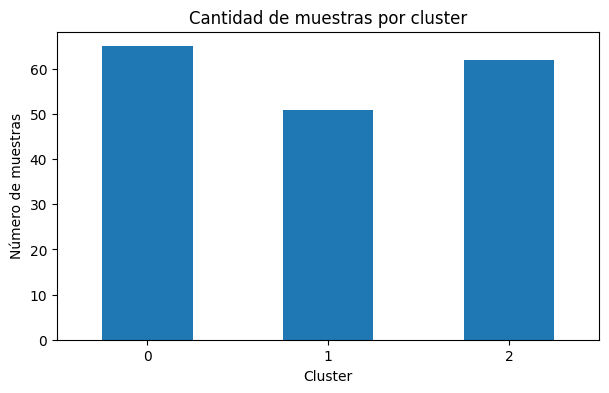

In [12]:
# Cantidad de registros por cluster
print("Cantidad de muestras por cluster:")
print(X_resultado["Cluster"].value_counts().sort_index())

# Gráfica de distribución
X_resultado["Cluster"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Cantidad de muestras por cluster")
plt.xlabel("Cluster")
plt.ylabel("Número de muestras")
plt.xticks(rotation=0)
plt.show()